In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("medical_cost.csv")
df.head(5)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.shape

(1338, 7)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

In [6]:
tr_kolon = {"age" : "yaş",
            "sex" : "cinsiyet",
            "bmi" : "vücut_kitle_indeksi",
            "children" : "cocuk_sayısı",
            "smoker" : "sigara_kullanımı",
            "region":"bölge",
            "charges" : "sağlık_sigortası_maliyeti"
            }

df = df.rename(columns=tr_kolon)

In [7]:
df.head()

,yaş,cinsiyet,vücut_kitle_indeksi,cocuk_sayısı,sigara_kullanımı,bölge,sağlık_sigortası_maliyeti
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [8]:
df.describe().T # sadece sayısal sütunlar

,count,mean,std,min,25%,50%,75%,max
yaş,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
vücut_kitle_indeksi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
cocuk_sayısı,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
sağlık_sigortası_maliyeti,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


In [9]:
df["bölge"].unique()

<StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str

In [10]:
bölge_degerleri = {"northeast" : "Kuzeydoğu",

                    "northwest": "Kuzeybatı",

                    "southeast": "Güneydoğu",

                    "southwest": "Güneybatı"    
                }


df["bölge"] = df["bölge"].map(bölge_degerleri)


In [11]:
df["bölge"].unique()

<StringArray>
['Güneybatı', 'Güneydoğu', 'Kuzeybatı', 'Kuzeydoğu']
Length: 4, dtype: str

In [12]:
df.head()

,yaş,cinsiyet,vücut_kitle_indeksi,cocuk_sayısı,sigara_kullanımı,bölge,sağlık_sigortası_maliyeti
0,19,female,27.900,0,yes,Güneybatı,16884.92400
1,18,male,33.770,1,no,Güneydoğu,1725.55230
2,28,male,33.000,3,no,Güneydoğu,4449.46200
3,33,male,22.705,0,no,Kuzeybatı,21984.47061
4,32,male,28.880,0,no,Kuzeybatı,3866.85520


In [13]:
cinsiyete_gore_cocuk_sayısı = df.groupby("cinsiyet")["cocuk_sayısı"].value_counts()
df_cinsiyete_gore_cocuk_sayısı = cinsiyete_gore_cocuk_sayısı.reset_index()  #  reset_index() pandas dataframe nesnesi döndürüyor.

df_cinsiyete_gore_cocuk_sayısı.T

,0,1,2,3,4,5,6,7,8,9,10,11
cinsiyet,female,female,female,female,female,female,male,male,male,male,male,male
cocuk_sayısı,0,1,2,3,4,5,0,1,2,3,4,5
count,289,158,119,77,11,8,285,166,121,80,14,10


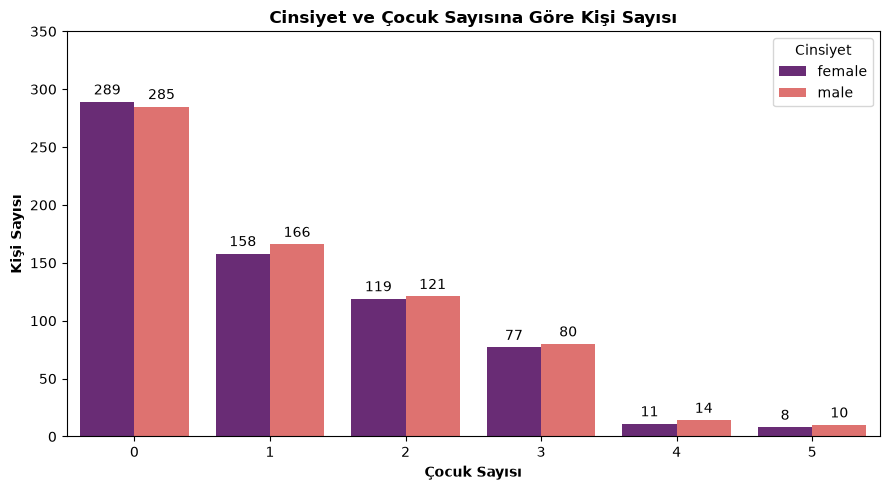

In [14]:
plt.figure(figsize=(9, 5))

grafik = sns.barplot(
    data = df_cinsiyete_gore_cocuk_sayısı,
    x = "cocuk_sayısı",
    y = "count",
    palette = "magma",  # rocket, mako, flare, crest, viridis, Blues, muted , magma
    hue = "cinsiyet"
)
# Sütunların üzerine değerleri yazdırma
for container in grafik.containers:
    grafik.bar_label(container, fmt="%.0f", padding=3)

plt.ylim(0,350)


plt.title("Cinsiyet ve Çocuk Sayısına Göre Kişi Sayısı" , fontweight = "bold")
plt.xlabel("Çocuk Sayısı" , fontweight = "bold")
plt.ylabel("Kişi Sayısı" , fontweight = "bold")
plt.legend(title="Cinsiyet")
plt.tight_layout()
plt.show()

In [15]:
cinsiyete_gore_sigara_durumu = df.groupby("cinsiyet")["sigara_kullanımı"].value_counts()
df_cinsiyete_gore_sigara_durumu = cinsiyete_gore_sigara_durumu.reset_index()
df_cinsiyete_gore_sigara_durumu

,cinsiyet,sigara_kullanımı,count
0,female,no,547
1,female,yes,115
2,male,no,517
3,male,yes,159


In [16]:
cinsiyete_gore_sigara_durum_oranı = df.groupby("cinsiyet")["sigara_kullanımı"].value_counts(normalize=True).round(2).reset_index()
cinsiyete_gore_sigara_durum_oranı

,cinsiyet,sigara_kullanımı,proportion
0,female,no,0.83
1,female,yes,0.17
2,male,no,0.76
3,male,yes,0.24


In [17]:
cinsiyete_gore_sigara_merge = pd.merge(df_cinsiyete_gore_sigara_durumu,cinsiyete_gore_sigara_durum_oranı ,on=["cinsiyet", "sigara_kullanımı"])
cinsiyete_gore_sigara_merge

,cinsiyet,sigara_kullanımı,count,proportion
0,female,no,547,0.83
1,female,yes,115,0.17
2,male,no,517,0.76
3,male,yes,159,0.24


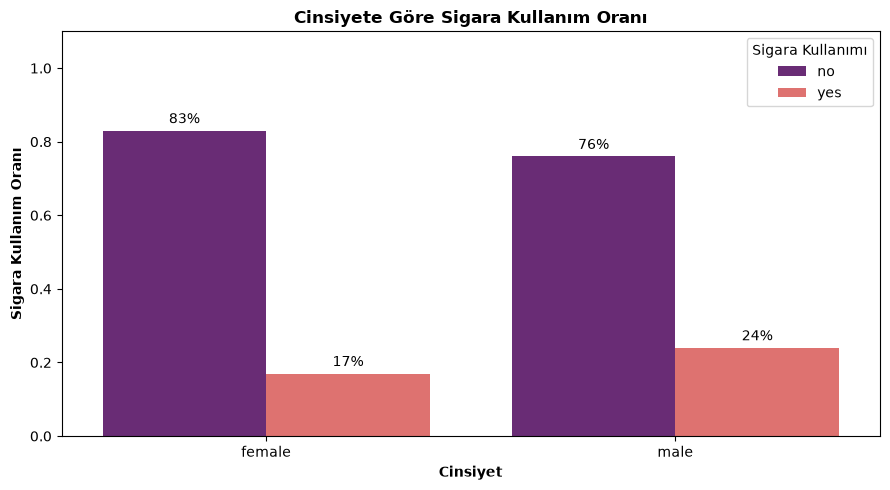

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))

ax = sns.barplot(
    data=cinsiyete_gore_sigara_merge,
    x="cinsiyet",
    y="proportion",

    hue="sigara_kullanımı",
    palette="magma",
)

# barların üzerine yüzdeleri yazdırma
for container in ax.containers:
  ax.bar_label(container, fmt='{:.0%}', padding=3)


ax.set_title("Cinsiyete Göre Sigara Kullanım Oranı",fontweight="bold")
ax.set_xlabel("Cinsiyet", fontweight="bold")
ax.set_ylabel("Sigara Kullanım Oranı", fontweight="bold")
ax.set_ylim(0, 1.1)


ax.legend(title="Sigara Kullanımı")


plt.tight_layout()
plt.show()

In [19]:
df.groupby("bölge")["yaş"].mean().round(2).reset_index().sort_values(by = "yaş" , ascending=False) # ascending : yükselen , artan demek

,bölge,yaş
0,Güneybatı,39.46
3,Kuzeydoğu,39.27
2,Kuzeybatı,39.20
1,Güneydoğu,38.94


In [20]:
grafik_groupby = df.groupby("bölge").agg({"yaş" : ["count","mean","min","max"],
                         "cocuk_sayısı" : ["mean"],
                         "sağlık_sigortası_maliyeti" : ["min","max","mean"]
                         
                         }).round(2).sort_values(("sağlık_sigortası_maliyeti","mean"),ascending=False).reset_index()

grafik_groupby

bölge   yaş                cocuk_sayısı sağlık_sigortası_maliyeti  \
             count   mean min max         mean                       min   
0  Güneydoğu   364  38.94  18  64         1.05                   1121.87   
1  Kuzeydoğu   324  39.27  18  64         1.05                   1694.80   
2  Kuzeybatı   325  39.20  19  64         1.15                   1621.34   
3  Güneybatı   325  39.46  19  64         1.14                   1241.56   

                       
        max      mean  
0  63770.43  14735.41  
1  58571.07  13406.38  
2  60021.40  12417.58  
3  52590.83  12346.94

Text(0, 0.5, 'Ortalama Sağlık Sigortası Maliyeti')

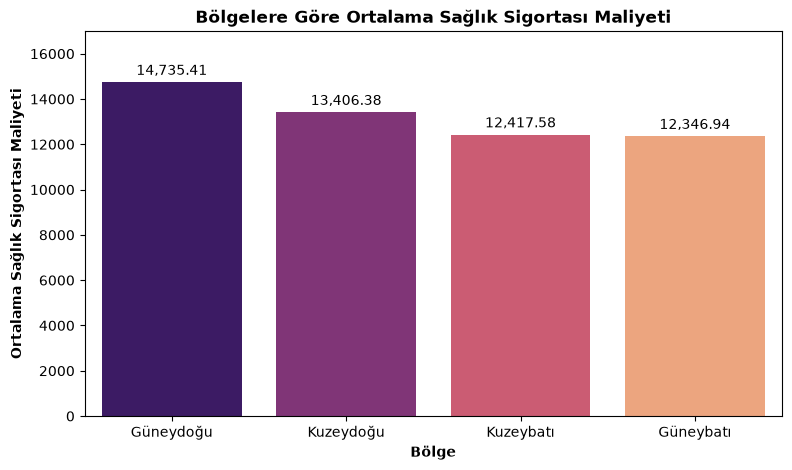

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    x=grafik_groupby[("bölge", "")], # buradaki "", sütun adının ikinci seviyesinin boş olduğunu ifade eder.
    y=grafik_groupby[("sağlık_sigortası_maliyeti", "mean")], # ortalama maliyet değerlerinin bulunduğu sütunu alıyoruz
    palette="magma",
    hue=grafik_groupby[("bölge", "")]
)

# sütunların üzerine ortalama maliyetleri yazdırma
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.2f}", padding=3)

ax.set_ylim(0,17000)

ax.set_title("Bölgelere Göre Ortalama Sağlık Sigortası Maliyeti",fontweight="bold")
ax.set_xlabel("Bölge", fontweight="bold")
ax.set_ylabel("Ortalama Sağlık Sigortası Maliyeti", fontweight="bold")


In [ ]:
# Yetişkinler için ideal Vücut Kitle İndeksi (VKİ) 18,5 ile 24,9 kg/m² arasındaki değerdir.
'''

• 18,5 kg/m² altı: Zayıf
• 18,5 - 24,9 kg/m² arası: Normal (Sağlıklı) kilolu
• 25,0 - 29,9 kg/m² arası: Şişman (Fazla kilolu)
• 30,0 - 34,9 kg/m² arası: 1. Derece Obezite
• 35,0 - 39,9 kg/m² arası: 2. Derece Obezite (Aşırı obez)
• 40,0 kg/m² ve üzeri: 3. Derece Obezite (Morbid obezite)

'''
def vki_siniflandırma(vki):
  if vki < 18.5:
    return "Zayıf"
  elif 18.5 <= vki < 25.0:
    return "Normal (Sağlıklı) kilolu"
  elif 25.0 <= vki < 30.0:
    return "Şişman (Fazla kilolu)"
  elif 30.0 <= vki < 35.0:
    return "1. Derece Obezite"
  elif 35.0 <= vki < 40.0:
    return "2. Derece Obezite (Aşırı obez)"
  else:
    return "3. Derece Obezite (Morbid obezite)"

# yeni kolon oluşturma
df["vücut_kitle_indeksi_sınıflandırma"] = df["vücut_kitle_indeksi"].apply(vki_siniflandırma)


In [23]:
df.head()

,yaş,cinsiyet,vücut_kitle_indeksi,cocuk_sayısı,sigara_kullanımı,bölge,sağlık_sigortası_maliyeti,vücut_kitle_indeksi_sınıflandırma
0,19,female,27.900,0,yes,Güneybatı,16884.92400,Şişman (Fazla kilolu)
1,18,male,33.770,1,no,Güneydoğu,1725.55230,1. Derece Obezite
2,28,male,33.000,3,no,Güneydoğu,4449.46200,1. Derece Obezite
3,33,male,22.705,0,no,Kuzeybatı,21984.47061,Normal (Sağlıklı) kilolu
4,32,male,28.880,0,no,Kuzeybatı,3866.85520,Şişman (Fazla kilolu)


In [24]:
df = df.reindex(columns=['yaş', 'cinsiyet', 'vücut_kitle_indeksi', 'vücut_kitle_indeksi_sınıflandırma',"cocuk_sayısı","sigara_kullanımı","bölge","sağlık_sigortası_maliyeti"])

# reindex : yeniden_indexleme

In [25]:
df.head()

,yaş,cinsiyet,vücut_kitle_indeksi,vücut_kitle_indeksi_sınıflandırma,cocuk_sayısı,sigara_kullanımı,bölge,sağlık_sigortası_maliyeti
0,19,female,27.900,Şişman (Fazla kilolu),0,yes,Güneybatı,16884.92400
1,18,male,33.770,1. Derece Obezite,1,no,Güneydoğu,1725.55230
2,28,male,33.000,1. Derece Obezite,3,no,Güneydoğu,4449.46200
3,33,male,22.705,Normal (Sağlıklı) kilolu,0,no,Kuzeybatı,21984.47061
4,32,male,28.880,Şişman (Fazla kilolu),0,no,Kuzeybatı,3866.85520


In [26]:
encod_sigara_kullanım = {"yes" : 1, "no" : 0}      

df["sigara_kullanımı"] = df["sigara_kullanımı"].map(encod_sigara_kullanım)

In [27]:
df_ozet = df.groupby("bölge").agg(
   
    sigara_kullanım_oranı=("sigara_kullanımı", "mean"),
    ortalama_sağlık_sigorta_maliyeti=("sağlık_sigortası_maliyeti", "mean")

).reset_index().round(2).sort_values("ortalama_sağlık_sigorta_maliyeti" , ascending = False)

df_ozet

,bölge,sigara_kullanım_oranı,ortalama_sağlık_sigorta_maliyeti
1,Güneydoğu,0.25,14735.41
3,Kuzeydoğu,0.21,13406.38
2,Kuzeybatı,0.18,12417.58
0,Güneybatı,0.18,12346.94


(0.0, 17000.0)

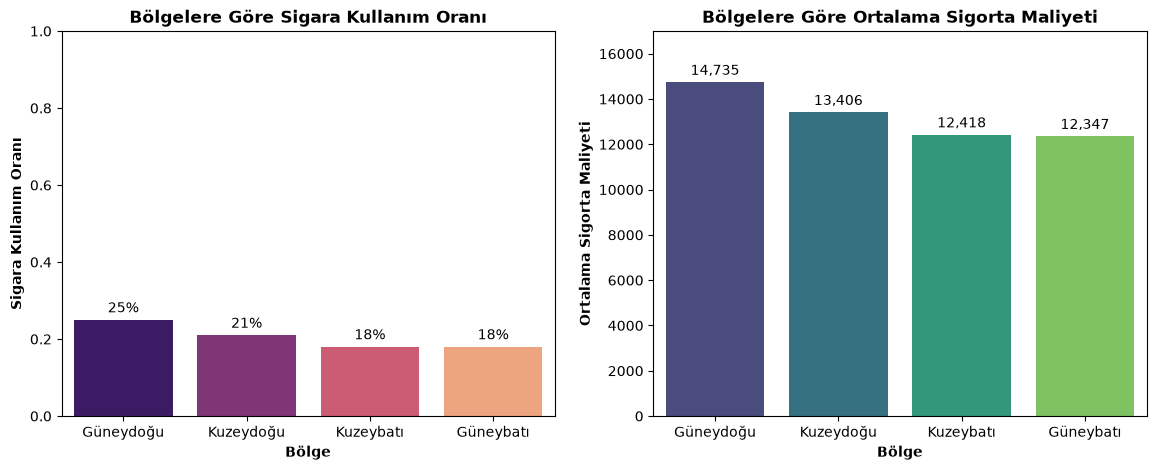

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=df_ozet,
    x="bölge",
    y="sigara_kullanım_oranı",
    order=df_ozet["bölge"],  # tabloda bölgeler hangi sıradaysa grafikte de o sırayla göster , çiz demek.
    palette="magma",  # rocket, mako, flare, crest, viridis, Blues, muted , magma
    hue = df_ozet["bölge"],
    ax=axes[0]
)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="{:.0%}", padding=3)

axes[0].set_title("Bölgelere Göre Sigara Kullanım Oranı",fontweight="bold")
axes[0].set_xlabel("Bölge", fontweight="bold")
axes[0].set_ylabel("Sigara Kullanım Oranı", fontweight="bold")
axes[0].set_ylim(0, 1)


sns.barplot(
    data=df_ozet,
    x="bölge",
    y="ortalama_sağlık_sigorta_maliyeti",
    order=df_ozet["bölge"],
    palette = "viridis",  # rocket, mako, flare, crest, viridis, Blues, muted , magma
    hue = df_ozet["bölge"],
    ax=axes[1]
)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="{:,.0f}", padding=3) # fmt = format demek

axes[1].set_title("Bölgelere Göre Ortalama Sigorta Maliyeti",fontweight="bold")
axes[1].set_xlabel("Bölge", fontweight="bold")
axes[1].set_ylabel("Ortalama Sigorta Maliyeti", fontweight="bold")
axes[1].set_ylim(0, 17000)


In [28]:
df.head()

,yaş,cinsiyet,vücut_kitle_indeksi,vücut_kitle_indeksi_sınıflandırma,cocuk_sayısı,sigara_kullanımı,bölge,sağlık_sigortası_maliyeti
0,19,female,27.900,Şişman (Fazla kilolu),0,1,Güneybatı,16884.92400
1,18,male,33.770,1. Derece Obezite,1,0,Güneydoğu,1725.55230
2,28,male,33.000,1. Derece Obezite,3,0,Güneydoğu,4449.46200
3,33,male,22.705,Normal (Sağlıklı) kilolu,0,0,Kuzeybatı,21984.47061
4,32,male,28.880,Şişman (Fazla kilolu),0,0,Kuzeybatı,3866.85520


In [47]:
grup_analiz = df.groupby("bölge").agg(sigara_kullanım_oranı = ("sigara_kullanımı" , "mean"),
                         ortalama_vücut_kitle_indexi = ("vücut_kitle_indeksi" , "mean"),
                         ortalama_sağlık_sigorta_maliyeti = ("sağlık_sigortası_maliyeti" , "mean")).round(2).sort_values("ortalama_vücut_kitle_indexi",ascending=False)

grup_analiz

,sigara_kullanım_oranı,ortalama_vücut_kitle_indexi,ortalama_sağlık_sigorta_maliyeti
bölge,,,
Güneydoğu,0.25,33.36,14735.41
Güneybatı,0.18,30.60,12346.94
Kuzeybatı,0.18,29.20,12417.58
Kuzeydoğu,0.21,29.17,13406.38


(0.0, 22000.0)

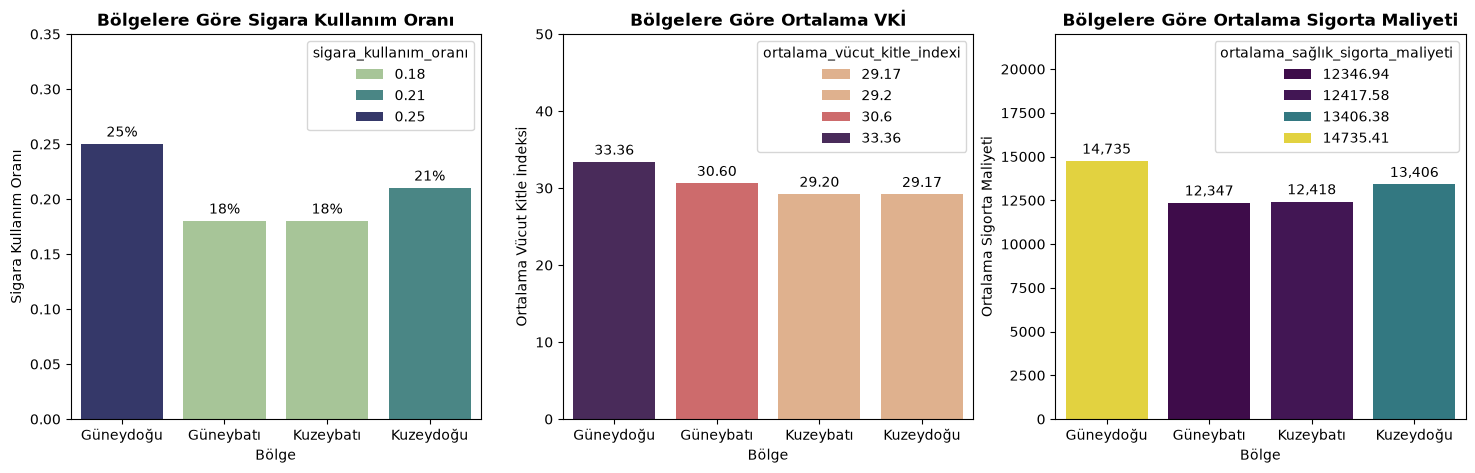

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(
    x = grup_analiz.index,  # tablomuz groupby ile oluşturduğumuz için "bölge" sütun değil index halinde şu an 
    y = grup_analiz["sigara_kullanım_oranı"],

    
    palette = "crest",   # rocket, mako, flare, crest, viridis, Blues, muted , magma
    hue = grup_analiz["sigara_kullanım_oranı"],
    ax = axes[0]
)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="{:.0%}", padding=3)

axes[0].set_title("Bölgelere Göre Sigara Kullanım Oranı", fontweight="bold")
axes[0].set_xlabel("Bölge")
axes[0].set_ylabel("Sigara Kullanım Oranı")
axes[0].set_ylim(0, 0.35)


sns.barplot(
    x=grup_analiz.index,
    y=grup_analiz["ortalama_vücut_kitle_indexi"],


    palette = "flare",   # rocket, mako, flare, crest, viridis, Blues, muted , magma
    hue = grup_analiz["ortalama_vücut_kitle_indexi"],
    ax=axes[1]
)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="{:.2f}", padding=3)

axes[1].set_title("Bölgelere Göre Ortalama VKİ", fontweight="bold")
axes[1].set_xlabel("Bölge")
axes[1].set_ylabel("Ortalama Vücut Kitle İndeksi")
axes[1].set_ylim(0,50)

sns.barplot(
    x=grup_analiz.index,
    y=grup_analiz["ortalama_sağlık_sigorta_maliyeti"],


    palette = "viridis",   # rocket, mako, flare, crest, viridis, Blues, muted , magma
    hue = grup_analiz["ortalama_sağlık_sigorta_maliyeti"],
    ax=axes[2]
)

for container in axes[2].containers:
    axes[2].bar_label(container, fmt="{:,.0f}", padding=3)

axes[2].set_title("Bölgelere Göre Ortalama Sigorta Maliyeti", fontweight="bold")
axes[2].set_xlabel("Bölge")
axes[2].set_ylabel("Ortalama Sigorta Maliyeti")
axes[2].set_ylim(0, 22000)


In [30]:
df3 = df.groupby("cinsiyet").agg(sigara_kullanım_oranı = ("sigara_kullanımı" , "mean"),
                           ortalama_cocuk_sayısı = ("cocuk_sayısı","mean"),
                           ortalam_sağlık_sigorta_maliyeti = ("sağlık_sigortası_maliyeti","mean")).round(2)

df3

,sigara_kullanım_oranı,ortalama_cocuk_sayısı,ortalam_sağlık_sigorta_maliyeti
cinsiyet,,,
female,0.17,1.07,12569.58
male,0.24,1.12,13956.75


Text(0, 0.5, 'Ortalam Sağlık Sigorta Maliyeti')

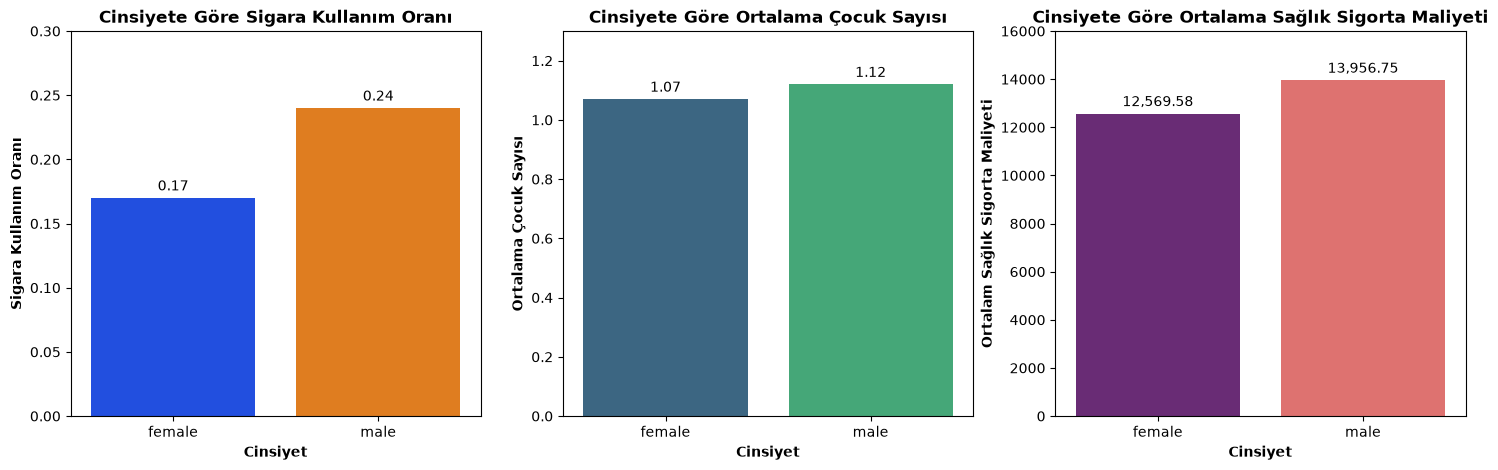

In [66]:
fig , axes = plt.subplots(1,3,figsize = (18,5))

grafik_1 = sns.barplot(
    data = df3,
    x = "cinsiyet",
    y = "sigara_kullanım_oranı",
    ax = axes[0],


    palette="bright",
    hue="cinsiyet"
)
for container in grafik_1.containers:
    grafik_1.bar_label(container, fmt="%.2f", padding=3)

axes[0].set_ylim(0,0.30)
axes[0].set_title("Cinsiyete Göre Sigara Kullanım Oranı",fontweight = "bold")
axes[0].set_xlabel("Cinsiyet" , fontweight = "bold")
axes[0].set_ylabel("Sigara Kullanım Oranı" ,fontweight = "bold")


grafik_2 = sns.barplot(
    data = df3,
    x = "cinsiyet",
    y = "ortalama_cocuk_sayısı",
    ax = axes[1],


    palette="viridis", # rocket, mako, flare, crest, viridis, Blues, muted
    hue="cinsiyet"
)

for container in grafik_2.containers:
    grafik_2.bar_label(container, fmt="%.2f", padding=3)

axes[1].set_ylim(0,1.30)
axes[1].set_title("Cinsiyete Göre Ortalama Çocuk Sayısı",fontweight = "bold")
axes[1].set_xlabel("Cinsiyet" , fontweight = "bold")
axes[1].set_ylabel("Ortalama Çocuk Sayısı" ,fontweight = "bold")


grafik_3 = sns.barplot(
    data = df3,
    x = "cinsiyet",
    y = "ortalam_sağlık_sigorta_maliyeti",
    ax = axes[2],


    palette="magma", # rocket, mako, flare, crest, viridis, Blues, muted , magma
    hue="cinsiyet"
)

for container in grafik_3.containers:
    grafik_3.bar_label(container, fmt="{:,.2f}", padding=3)

axes[2].set_ylim(0,16000)
axes[2].set_title("Cinsiyete Göre Ortalama Sağlık Sigorta Maliyeti",fontweight = "bold")
axes[2].set_xlabel("Cinsiyet" , fontweight = "bold")
axes[2].set_ylabel("Ortalam Sağlık Sigorta Maliyeti" ,fontweight = "bold")